In [7]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
import statsmodels.api as sm

warnings.filterwarnings('ignore')
warnings.simplefilter(action='ignore', category=pd.errors.PerformanceWarning)

In [8]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load Data

In [9]:
datafolder = "../data"
spadl_h5   = os.path.join(datafolder, "women-statsbomb3.h5")   

In [ ]:
# ── Load combined long-format feature table (men + women, all tournaments) 
long_df = pd.read_hdf(spadl_h5, "combined_features_long")

# ── Load EFA tempo index and append as an extra metric row 
efa_df = pd.read_hdf(spadl_h5, "efa_tempo_index")[
    ["game_id", "possession", "possession_team_id", "tournament", "gender", "TI_horst"] #TI_efa
].copy()

# z-score TI_efa globally (already ~unit-variance but centre it like the others)
efa_df["value"] = efa_df["TI_horst"]
efa_df["value_z"] = (efa_df["value"] - efa_df["value"].mean()) / efa_df["value"].std(ddof=0)
efa_df["metric"] = "TI_horst"
# carry minimal ID columns that match long_df
efa_long = efa_df[["game_id", "possession", "possession_team_id",
                    "gender", "tournament", "metric", "value", "value_z"]].copy()

# Merge season / competition IDs back for efa rows
combined_wide = pd.read_hdf(spadl_h5, "combined_features")[
    ["game_id", "season_id", "competition_id", "period_id"]
].drop_duplicates("game_id")
efa_long = efa_long.merge(combined_wide, on="game_id", how="left")

long_df = pd.concat([long_df, efa_long], ignore_index=True)

print(f"Long-format rows total  : {len(long_df):,}")
print(long_df.groupby("metric")["value"].agg(["count","mean","std"]).round(3).to_string())

Long-format rows total  : 332,686
                                      count    mean    std
metric                                                    
TI_horst                              39995   0.000  1.000
baseline_meters_per_second            42904   8.947  2.920
baseline_meters_per_touch_per_second  42445   1.782  2.402
baseline_passes_per_min               43773  19.265  8.051
baseline_time_to_pass                 38446   3.475  1.429
distance_per_second                   42904   8.947  2.920
inter_pass_interval                   38446   3.475  1.429
passes_per_minute                     43773  19.265  8.051


## Data Preparation for LMM

In [ ]:
# ── Metric sets 
LATENT  = ["TI_horst"]

BASELINE = [
    "baseline_passes_per_min",
    "baseline_time_to_pass",
    "baseline_meters_per_touch_per_second",
    "baseline_meters_per_second",
]

ALL_METRICS = LATENT + BASELINE   # 5 metrics total

# ── Tournament ordering (chronological within gender) 
TOURN_YEAR = {
    "EURO2020":   2021,
    "WC2022":     2022,
    "WEURO2022":  2022,
    "WWC2023":    2023,
    "EURO2024":   2024,
    "WEURO2025":  2025,
}
TOURN_ORDER = sorted(TOURN_YEAR, key=TOURN_YEAR.get)

REF_GENDER = "Women"
REF_TOURN  = "WEURO2022"

efa_keys = (
    long_df[long_df["metric"] == "TI_horst"]
    [["game_id", "possession", "possession_team_id"]]
    .drop_duplicates()
)

df = (
    long_df[long_df["metric"].isin(ALL_METRICS)]
    .merge(efa_keys, on=["game_id", "possession", "possession_team_id"], how="inner")
    .copy()
)

df["gender"]     = pd.Categorical(df["gender"],     categories=["Women", "Men"])
df["tournament"] = pd.Categorical(df["tournament"], categories=TOURN_ORDER)
df["year"]       = df["tournament"].map(TOURN_YEAR)

print("Possessions per metric (restricted to TI_efa 360-data subset):")
print(df.groupby("metric")["value_z"].count().reindex(ALL_METRICS).to_string())
print(f"\nTournaments  : {TOURN_ORDER}")
print(f"Gender ref   : {REF_GENDER}  |  Tournament ref : {REF_TOURN}")

Possessions per metric (restricted to TI_efa 360-data subset):
metric
TI_horst                                39995
baseline_passes_per_min                 39995
baseline_time_to_pass                   37239
baseline_meters_per_touch_per_second    39875
baseline_meters_per_second              39995

Tournaments  : ['EURO2020', 'WC2022', 'WEURO2022', 'WWC2023', 'EURO2024', 'WEURO2025']
Gender ref   : Women  |  Tournament ref : WEURO2022


## LMM — (i) Gender Sensitivity

Model per metric:

$$\text{value\_z}_{ij} = \beta_0 + \beta_1 \cdot \text{gender}_{ij} + u_j + \varepsilon_{ij}$$

- Fixed effect: gender (Men vs Women, dummy-coded)  
- Random intercept: game\_id (possessions within the same game are clustered)  
- **Sensitivity** = |β₁| with 95% CI; larger |β₁| means the metric better distinguishes Men from Women

In [12]:
def _fit_mixedlm(formula, data, groups, reml=True):
    """Fit MixedLM trying multiple optimizers; return the result with highest llf."""
    md = smf.mixedlm(formula, data=data, groups=groups)
    best = None
    for method in ("powell", "bfgs", "lbfgs", "nm"):
        try:
            res = md.fit(method=method, reml=reml, disp=False)
            if best is None or res.llf > best.llf:
                best = res
        except Exception:
            continue
    if best is None:
        raise RuntimeError(f"All optimizers failed for: {formula}")
    return best


def fit_gender_lmm(data, metric):
    """Fit value_z ~ gender + (1|game_id) for a single metric."""
    sub = data[data["metric"] == metric].dropna(subset=["value_z", "gender", "game_id"])
    mdf = _fit_mixedlm(
        "value_z ~ C(gender, Treatment('Women'))", sub, sub["game_id"]
    )
    coef_name = "C(gender, Treatment('Women'))[T.Men]"
    coef  = mdf.params[coef_name]
    ci    = mdf.conf_int().loc[coef_name]
    pval  = mdf.pvalues[coef_name]
    return dict(metric=metric, coef=coef, ci_lo=ci[0], ci_hi=ci[1],
                pval=pval, n=int(mdf.nobs), n_games=sub["game_id"].nunique())

gender_rows = [fit_gender_lmm(df, m) for m in ALL_METRICS]
gender_res  = pd.DataFrame(gender_rows).set_index("metric").reindex(ALL_METRICS)
gender_res["sig"] = gender_res["pval"].apply(
    lambda p: "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else ""))
)
gender_res["abs_coef"] = gender_res["coef"].abs()

print("=== Gender sensitivity (β₁: Men vs Women, ref=Women) ===")
print(gender_res[["coef","ci_lo","ci_hi","pval","sig","n","n_games"]].round(4).to_string())

=== Gender sensitivity (β₁: Men vs Women, ref=Women) ===
                                        coef   ci_lo   ci_hi    pval  sig      n  n_games
metric                                                                                   
TI_horst                              0.5043  0.4471  0.5614  0.0000  ***  39995      292
baseline_passes_per_min               0.0571  0.0281  0.0862  0.0001  ***  39995      292
baseline_time_to_pass                -0.1375 -0.1708 -0.1043  0.0000  ***  37239      292
baseline_meters_per_touch_per_second -0.0340 -0.0546 -0.0135  0.0012   **  39875      292
baseline_meters_per_second            0.1617  0.1304  0.1930  0.0000  ***  39995      292


## LMM — (ii) Temporal Evolution

Two sub-models per metric:

**Linear trend within gender** — does the metric capture year-on-year change?

$$\text{value\_z}_{ij} = \beta_0 + \beta_1 \cdot \text{year}_{ij} + u_j + \varepsilon_{ij}$$

**Tournament effect (categorical)** — omnibus test via likelihood ratio (LR):  
full model `~ tournament` vs. null model `~ 1`, random intercept `game_id` in both.

In [ ]:
def fit_temporal_lmm(data, metric):
    """
    1. Linear year trend (value_z ~ year + (1|game_id)) within each gender.
    2. Categorical tournament LR test: full vs null (ML, not REML).
    """
    sub = data[data["metric"] == metric].dropna(
        subset=["value_z", "year", "tournament", "game_id", "gender"]
    )

    # ── 1. Linear year trend within each gender 
    results = {}
    for gender in ["Women", "Men"]:
        g = sub[sub["gender"] == gender]
        if g["year"].nunique() < 2:
            results[f"year_slope_{gender}"] = np.nan
            results[f"year_pval_{gender}"]  = np.nan
            continue
        mdf = _fit_mixedlm("value_z ~ year", g, g["game_id"])
        results[f"year_slope_{gender}"] = mdf.params["year"]
        results[f"year_pval_{gender}"]  = mdf.pvalues["year"]

    # ── 2. Tournament LR test (ML so llf are comparable) 
    mdf_full = _fit_mixedlm(
        f"value_z ~ C(tournament, Treatment('{REF_TOURN}'))",
        sub, sub["game_id"], reml=False
    )
    mdf_null = _fit_mixedlm(
        "value_z ~ 1", sub, sub["game_id"], reml=False
    )

    lr_stat = 2 * (mdf_full.llf - mdf_null.llf)
    df_diff = len(mdf_full.params) - len(mdf_null.params)
    # Guard: negative LR indicates both models converged poorly; report NaN
    if lr_stat < 0:
        lr_stat, lr_p = np.nan, np.nan
    else:
        lr_p = stats.chi2.sf(lr_stat, df=df_diff)

    var_fixed   = mdf_full.predict().var()
    var_rand    = float(mdf_full.cov_re.values[0][0])
    var_resid   = mdf_full.scale
    r2_marginal = var_fixed / (var_fixed + var_rand + var_resid)

    return dict(
        metric=metric,
        **results,
        lr_chi2=lr_stat,
        lr_df=df_diff,
        lr_p=lr_p,
        r2_marginal=r2_marginal,
        n=int(mdf_full.nobs),
    )


temporal_rows = [fit_temporal_lmm(df, m) for m in ALL_METRICS]
temporal_res  = pd.DataFrame(temporal_rows).set_index("metric").reindex(ALL_METRICS)
temporal_res["lr_sig"] = temporal_res["lr_p"].apply(
    lambda p: "***" if p < 0.001 else ("**" if p < 0.01 else ("*" if p < 0.05 else ""))
    if pd.notna(p) else "conv.fail"
)

print("=== Temporal evolution — linear year slope within gender ===")
print(temporal_res[["year_slope_Women","year_pval_Women",
                     "year_slope_Men","year_pval_Men"]].round(4).to_string())
print()
print("=== Tournament LR test (categorical omnibus) ===")
print(temporal_res[["lr_chi2","lr_df","lr_p","lr_sig","r2_marginal","n"]].round(4).to_string())

=== Temporal evolution — linear year slope within gender ===
                                      year_slope_Women  year_pval_Women  year_slope_Men  year_pval_Men
metric                                                                                                
TI_horst                                        0.0291           0.1006          0.0176         0.3095
baseline_passes_per_min                         0.0140           0.2226         -0.0093         0.2075
baseline_time_to_pass                           0.0051           0.6980          0.0189         0.0241
baseline_meters_per_touch_per_second           -0.0074           0.3021         -0.0055         0.3512
baseline_meters_per_second                     -0.0442           0.0000         -0.0317         0.0002

=== Tournament LR test (categorical omnibus) ===
                                       lr_chi2  lr_df    lr_p lr_sig  r2_marginal      n
metric                                                                         

## Sensitivity Comparison — Forest Plots

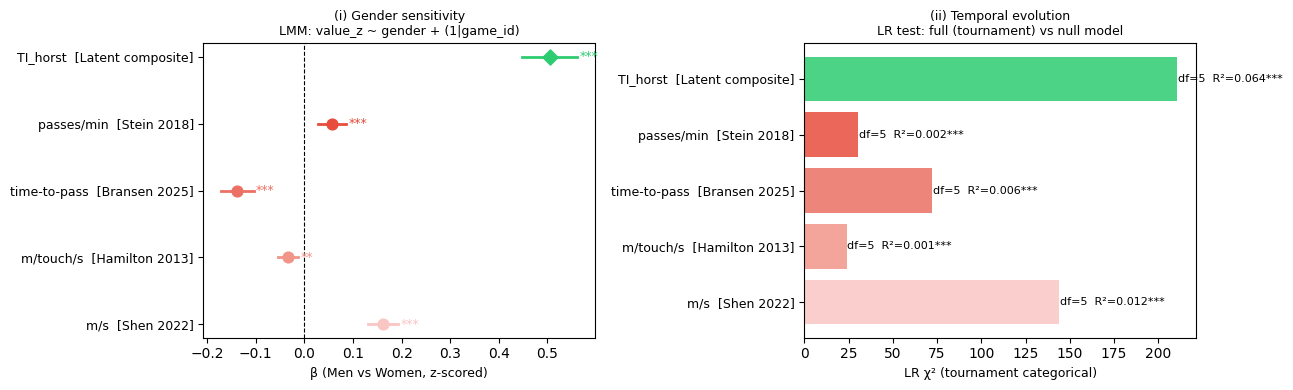

In [ ]:
METRIC_LABELS = {
    "TI_horst":                              "TI_horst  [Latent composite]",
    "baseline_passes_per_min":             "passes/min  [Stein 2018]",
    "baseline_time_to_pass":               "time-to-pass  [Bransen 2025]",
    "baseline_meters_per_touch_per_second":"m/touch/s  [Hamilton 2013]",
    "baseline_meters_per_second":          "m/s  [Shen 2022]",
}
COLORS = {
    "TI_horst":                              "#2ecc71",
    "baseline_passes_per_min":             "#e74c3c",
    "baseline_time_to_pass":               "#ec7063",
    "baseline_meters_per_touch_per_second":"#f1948a",
    "baseline_meters_per_second":          "#f9c6c3",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# ── Panel A: Gender effect (forest plot)
ax = axes[0]
y_pos = np.arange(len(ALL_METRICS))
for i, m in enumerate(ALL_METRICS):
    row   = gender_res.loc[m]
    color = COLORS[m]
    ax.plot([row["ci_lo"], row["ci_hi"]], [i, i], color=color, lw=2)
    ax.scatter(row["coef"], i, color=color, zorder=5, s=60,
               marker="D" if m == "TI_horst" else "o")
    if row["sig"]:
        ax.text(row["ci_hi"] + 0.005, i, row["sig"], va="center", fontsize=9, color=color)

ax.axvline(0, color="black", lw=0.8, ls="--")
ax.set_yticks(y_pos)
ax.set_yticklabels([METRIC_LABELS[m] for m in ALL_METRICS], fontsize=9)
ax.set_xlabel("β (Men vs Women, z-scored)", fontsize=9)
ax.set_title("(i) Gender sensitivity\nLMM: value_z ~ gender + (1|game_id)", fontsize=9)
ax.invert_yaxis()

# ── Panel B: Tournament LR chi² (bar chart) ──────────────────────────────────
ax = axes[1]
chi2_vals  = temporal_res.reindex(ALL_METRICS)["lr_chi2"].values
colors_bar = [COLORS[m] for m in ALL_METRICS]

ax.barh(y_pos, chi2_vals, color=colors_bar, alpha=0.85)
ax.set_yticks(y_pos)
ax.set_yticklabels([METRIC_LABELS[m] for m in ALL_METRICS], fontsize=9)
ax.set_xlabel("LR χ² (tournament categorical)", fontsize=9)
ax.set_title("(ii) Temporal evolution\nLR test: full (tournament) vs null model", fontsize=9)
ax.invert_yaxis()

for i, m in enumerate(ALL_METRICS):
    row = temporal_res.loc[m]
    ax.text(chi2_vals[i] + 0.5, i,
            f"df={int(row['lr_df'])}  R²={row['r2_marginal']:.3f}{row['lr_sig']}",
            va="center", fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
# ── Summary table 
summary = pd.DataFrame({
    "label":        [METRIC_LABELS[m] for m in ALL_METRICS],
    "gender_β":     gender_res.reindex(ALL_METRICS)["coef"].round(3),
    "gender_95CI":  [f"[{gender_res.loc[m,'ci_lo']:.3f}, {gender_res.loc[m,'ci_hi']:.3f}]"
                     for m in ALL_METRICS],
    "gender_sig":   gender_res.reindex(ALL_METRICS)["sig"],
    "year_β_Women": temporal_res.reindex(ALL_METRICS)["year_slope_Women"].round(4),
    "year_β_Men":   temporal_res.reindex(ALL_METRICS)["year_slope_Men"].round(4),
    "LR_χ²":        temporal_res.reindex(ALL_METRICS)["lr_chi2"].round(1),
    "R²_marg":      temporal_res.reindex(ALL_METRICS)["r2_marginal"].round(4),
    "tourn_sig":    temporal_res.reindex(ALL_METRICS)["lr_sig"],
}, index=ALL_METRICS)

print("=" * 100)
print("SENSITIVITY COMPARISON SUMMARY  (TI_efa vs 4 baselines)")
print("=" * 100)
print(summary.to_string())
print()
print("gender_β  : LMM coefficient (Men − Women) on winsorised z-scored metric; 95% CI in brackets")
print("year_β    : LMM slope per calendar year within gender (linear time trend)")
print("LR_χ²     : likelihood-ratio χ² for tournament (categorical) fixed effect")
print("R²_marg   : marginal R² of tournament model (variance explained by fixed effects)")

SENSITIVITY COMPARISON SUMMARY  (TI_efa vs 4 baselines)
                                                             label  gender_β       gender_95CI gender_sig  year_β_Women  year_β_Men  LR_χ²  R²_marg tourn_sig
TI_horst                              TI_horst  [Latent composite]     0.504    [0.447, 0.561]        ***        0.0291      0.0176  210.8   0.0638       ***
baseline_passes_per_min                   passes/min  [Stein 2018]     0.057    [0.028, 0.086]        ***        0.0140     -0.0093   30.3   0.0018       ***
baseline_time_to_pass                 time-to-pass  [Bransen 2025]    -0.138  [-0.171, -0.104]        ***        0.0051      0.0189   72.2   0.0057       ***
baseline_meters_per_touch_per_second    m/touch/s  [Hamilton 2013]    -0.034  [-0.055, -0.013]         **       -0.0074     -0.0055   23.8   0.0009       ***
baseline_meters_per_second                        m/s  [Shen 2022]     0.162    [0.130, 0.193]        ***       -0.0442     -0.0317  144.1   0.0122       